# **Tarea  4 | Notebook de métricas de clasificación**
### Introducción a la Ciencia de Datos
*Alumno: Norman O. Guzmán Chaboya*

In [1]:
import os
import zipfile
import urllib.request
from io import BytesIO

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
plt.style.use('bmh')
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay


ran = 42

## 0. Dataset

Los datos corresponden a Bank Marketing del *UCI Machine Learning Repository*, y reúnen las campañas de mercadotecnia telefónica de un banco portugués realizadas entre mayo de 2008 y noviembre de 2010 (Moro et al., 2014). En cada llamada se ofrecía a un cliente un depósito a plazo; la variable objetivo `y` registra si el cliente lo contrató.

El archivo del repositorio (`bank+marketing.zip`) contiene a `bank-additional-full.csv` (41,188 registros, separados por punto y coma) y su descripción, `bank-additional-names.txt`, entre otros archivos que se descartaron, ya que no son requeridos para resolver esta tarea:

In [2]:
url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"

externo = zipfile.ZipFile(BytesIO(urllib.request.urlopen(url).read()))   # bank+marketing.zip
interno = zipfile.ZipFile(BytesIO(externo.read("bank-additional.zip")))  # bank-additional.zip
interno.extract("bank-additional/bank-additional-full.csv")
interno.extract("bank-additional/bank-additional-names.txt")

carpeta = "./bank-additional"

In [3]:
data = pd.read_csv(os.path.join(carpeta, "bank-additional-full.csv"), sep=";")
print(f"{data.shape[0]:,} registros, {data.shape[1]} columnas")
data.head(5)

41,188 registros, 21 columnas


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


### 0.1. Atributos

De acuerdo con el descriptor, cada llamada se describe por 20 atributos, agrupados en cuatro bloques:

**Datos del cliente**
- `age`: Edad (numérica)
- `job`: Tipo de empleo (categórica)
- `marital`: Estado civil (categórica)
- `education`: Nivel educativo (categórica)
- `default`: ¿Tiene crédito en incumplimiento? (categórica)
- `housing`: ¿Tiene crédito hipotecario? (categórica)
- `loan`: ¿Tiene crédito personal? (categórica)

**Último contacto de la campaña actual**
- `contact`: Tipo de comunicación, celular o teléfono fijo (categórica)
- `month`, `day_of_week`: Mes y día de la semana del último contacto (categóricas)
- `duration`: Duración del último contacto, en segundos (numérica)

**Otros atributos de campaña**
- `campaign`: Número de contactos en esta campaña, incluido el último (numérica)
- `pdays`: Días desde el último contacto en una campaña anterior; 999 indica que no hubo contacto previo (numérica)
- `previous`: Número de contactos antes de esta campaña (numérica)
- `poutcome`: Resultado de la campaña anterior (categórica)

**Contexto socioeconómico**
- `emp.var.rate`: Tasa de variación del empleo, trimestral
- `cons.price.idx`: Índice de precios al consumidor, mensual
- `cons.conf.idx`: Índice de confianza del consumidor, mensual
- `euribor3m`: Tasa Euribor a 3 meses, diaria
- `nr.employed`: Número de empleados, trimestral

In [4]:
cols_num = data.select_dtypes(include="number").columns
cols_cat = data.select_dtypes(exclude="number").columns.drop("y")

var_info = pd.DataFrame({
    "datatype": data[cols_num].dtypes.astype(str),
    "únicos": data[cols_num].nunique(),
    "min": data[cols_num].min(),
    "max": data[cols_num].max(),
})
var_info

,datatype,únicos,min,max
age,int64,78,17.000,98.000
duration,int64,1544,0.000,4918.000
campaign,int64,42,1.000,56.000
pdays,int64,27,0.000,999.000
previous,int64,8,0.000,7.000
emp.var.rate,float64,10,-3.400,1.400
cons.price.idx,float64,26,92.201,94.767
cons.conf.idx,float64,26,-50.800,-26.900
euribor3m,float64,316,0.634,5.045
nr.employed,float64,11,4963.600,5228.100


Observamos el rango de las variables númericas. `pdays` que corresponde al número de días pasados desde el último contacto con el cliente, contiene el atípico 999, el cual corresponde a los casos en los que no hubo un contacto previo

### 0.2. Variable Objetivo

`y`, binaria. Se revisa cuántos clientes hay en cada clase:

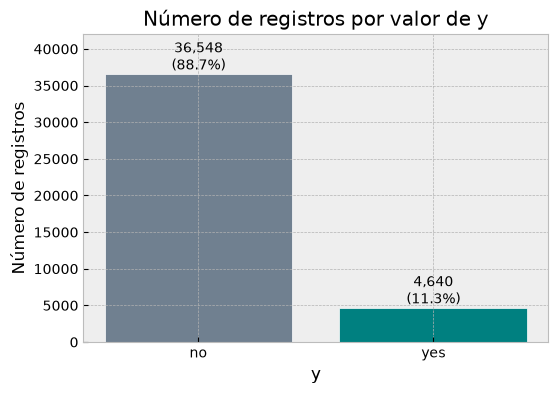

In [5]:
obj = "y"
conteo = data[obj].value_counts()

with plt.style.context('bmh'):
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(conteo.index, conteo.values, color=["slategrey", "teal"], edgecolor="white")
    for i, v in enumerate(conteo.values):
        ax.text(i, v, f"{v:,}\n({v / conteo.sum():.1%})", ha="center", va="bottom")
    ax.set_title(f"Número de registros por valor de {obj}")
    ax.set_xlabel(obj)
    ax.set_ylabel("Número de registros")
    ax.set_ylim(0, conteo.max() * 1.15)
    plt.show()

Las clases están fuertemente desbalanceadas: 1 de cada 10 contrató únicamente.

### 0.3. Valores faltante

De acuerdo al descriptor y una exploración empírica, los faltantes se codifican con la cadena `"unknown"` y en el valor 999 de `pdays`. Se cuentan ambos, junto con los registros duplicados:

In [6]:
print(f"Celdas vacías (NaN): {data.isna().sum().sum()}")
print(f"Registros duplicados: {data.duplicated().sum()}")
print(f"pdays = 999 (sin contacto previo): {(data['pdays'] == 999).sum():,} ({(data['pdays'] == 999).mean():.1%})")

desconocidos = (data[cols_cat] == "unknown").sum()
desconocidos = desconocidos[desconocidos > 0].sort_values(ascending=False)
pd.DataFrame({"unknown": desconocidos, "%": (desconocidos / len(data) * 100).round(2)})

Celdas vacías (NaN): 0
Registros duplicados: 12
pdays = 999 (sin contacto previo): 39,673 (96.3%)


,unknown,%
default,8597,20.87
education,1731,4.20
housing,990,2.40
loan,990,2.40
job,330,0.80
marital,80,0.19


Cómo ya se había mencionado previamente, el valor 999 en `pdays` corresponde al hecho de que el cliente no ha sido contactado previamente, que por lo visto corresponde a la gran mayoría de las instancias reportadas en el conjunto de datos (96.3%). Además, se tienen 12 registros duplicados y faltantes significativos en la clase `default`, que describe si el crédito del cliente está en default o no. 

Eliminamos los duplicados, que representan un porcentaje despreciable respecto al total:

In [7]:
data = data.drop_duplicates().reset_index(drop=True)
print(f"Registros tras eliminar duplicados: {len(data):,}")

Registros tras eliminar duplicados: 41,176


### 0.4. Distribución 

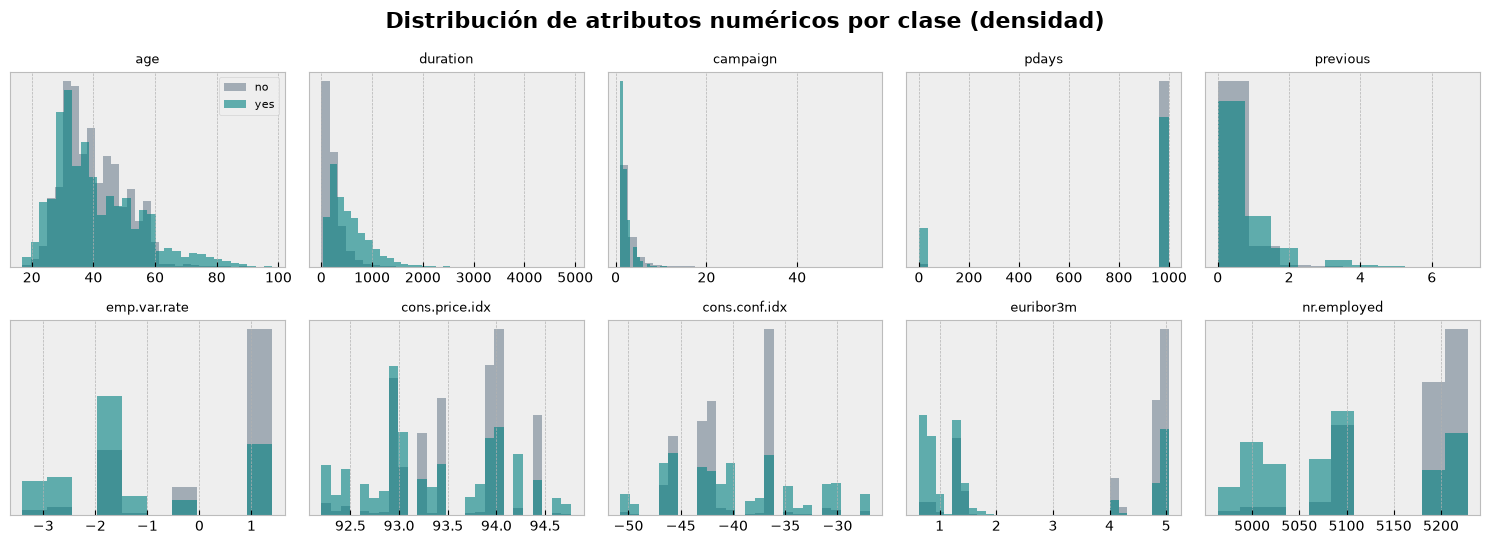

In [8]:
fig, axes = plt.subplots(2, 5, figsize=(15, 5.5))

with plt.style.context('bmh'):
    for ax, col in zip(axes.ravel(), cols_num):
        for clase, color in [("no", "slategrey"), ("yes", "teal")]:
            ax.hist(data.loc[data[obj] == clase, col], bins=min(data[col].nunique(), 30),
                    color=color, alpha=0.6, density=True, label=clase)
        ax.set_title(col, fontsize=9)
        ax.set_yticks([])
    axes[0, 0].legend(fontsize=8)

    fig.suptitle("Distribución de atributos numéricos por clase (densidad)",
                 fontsize=16, fontweight="bold")
    plt.tight_layout()
    plt.show()

 `campaign`, `previous` y `duration` se concentran en valores bajos con colas largas. Virtualmente, `pdays` solamente reporta 999, valores diferentes son casi inexistentes, por eso podemos asumir que esta variable esta fuertemente relacionada con la variable objetivo. 

### 1.5. Correlación

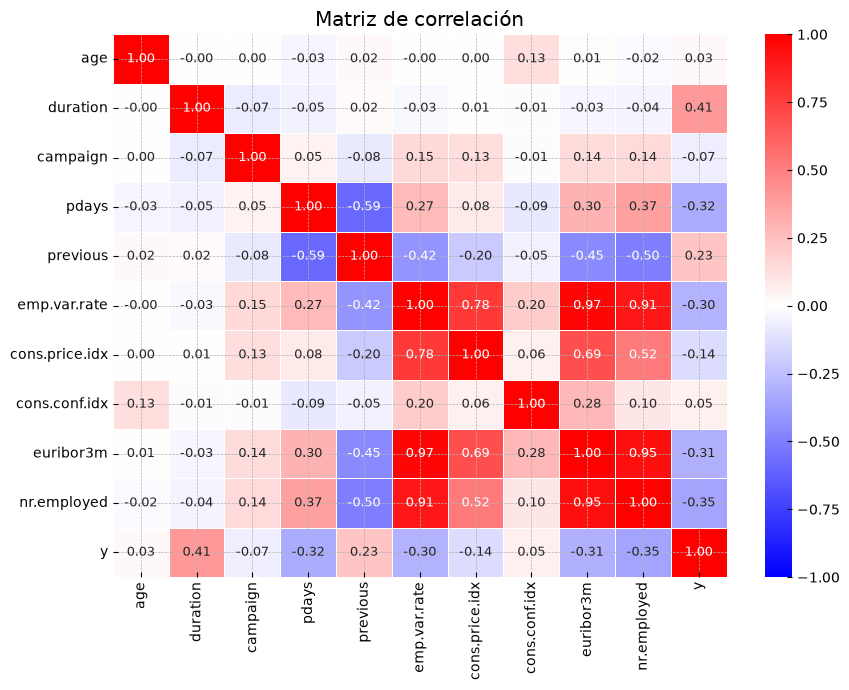

In [9]:
y_bin = (data[obj] == "yes").astype(int)
data[cols_num].corrwith(y_bin).sort_values(ascending=False).round(2).to_frame()

correlaciones = data[cols_num].assign(y=y_bin).corr()

fig, ax = plt.subplots(figsize=(9, 7))

sns.heatmap(correlaciones, cmap="bwr", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 9},
            linewidths=0.6, linecolor="white", ax=ax)

ax.set_title("Matriz de correlación")
plt.tight_layout()
plt.show()

`duration` es, con diferencia, el atributo más asociado con la aceptación; esto va muy de la mano con el hecho de solamente la tienen reportados los casos en los que hubo una llamada de vuelta, al igual que `pdays` que contribuye inversamente en una razón similar. Le siguen, , `nr.employed` y `euribor3m`. Los cinco indicadores socioeconómicos están fuertemente correlacionados entre sí `emp.var.rate`, `euribor3m` y `nr.employed`, por lo que aportan información muy redundante.

## 1. Variable Desconocida (para la mayoría de casos)

Antes de avanzar a lo siguiente, es importante notar que existe una variable de la que el banco no tiene conocimiento alguno antes de hacer una llamada a un contacto previo. Si nos detenemos a leer la información que el descriptor [descriptor](./bank-additional/bank-additional-names.txt) proporciona para la variable `duration`, y como se había notado durante la exploración:

>...last contact duration, in seconds (numeric). Important note:  this attribute highly affects the output target (e.g., if duration=0 then y="no"). Yet, **the duration is not known before a call is performed**. Also, after the end of the call y is obviously known. Thus, this input should only be included for benchmark purposes and should be discarded if the intention is to have a realistic predictive model...


Explícitamente, los autores del *dataset* declararon que no se tiene conocimiento de esta información sin haber antes realizado la llamada, por lo que para el uso del objetivo planeteado para este trabajo, no conviene tomar en cuenta como atributo. Lo siguiente entonces es simplemente eliminar la columna del conjunto:

In [10]:
X = data.drop(columns=["duration", obj])
y = y_bin

print(X.columns)

Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'campaign', 'pdays', 'previous',
       'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx',
       'euribor3m', 'nr.employed'],
      dtype='str')


## 2. Partición Estratificada y *baseline* (Siempre "No")

Se aparta el 20 % de los registros para prueba. La partición es estratificada por `y`, de modo que ambos conjuntos conserven la proporción de clientes que aceptó:

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=ran
)

pd.DataFrame({
    "registros": [len(y_train), len(y_test)],
    "% positivos": [y_train.mean() * 100, y_test.mean() * 100],
}, index=["entrenamiento", "prueba"]).round(2)

,registros,% positivos
entrenamiento,32940,11.27
prueba,8236,11.27


Como referencia, se evalúa en prueba un clasificador que siempre responde "No":

In [12]:
siempre_no = DummyClassifier(strategy="constant", constant=0).fit(X_train, y_train)
pred_no = siempre_no.predict(X_test)

print(f"Exactitud: {accuracy_score(y_test, pred_no):.4f}")

Exactitud: 0.8873


El clasificador que siempre responde "No" alcanza una exactitud cercana de ~89%, que coincide con lo que se muestra en el histograma de distribución de la clase-objetivo. Como se notaba al analizar el anterior gráfico, el desbalance entre las clases es extremo y juega un influencia engañosa con los resultados de la clasificación del *baseline*: los resultado, de acuerdo con la exactitud calculada parecen muy favorables, pero si se recuerda la fórmula para calcularle
$$\text{Accuracy} = \frac{VP + VN}{VP + VN + FP + FN}$$
la métrica favorece el desbalance a favor de la clase mayoritaria, ocultando el hecho de que simplemente estamos clasificando todo como "No" por medio de este clasificador *dummy*, y al ver tan pocos casos contrarios, el resultado pareciera favorable

## 3. Aplicando Regresión Logística

Primero, codificamos los atributos categóricos usando la función `OneHotEncoder()`  y escalamos las variables numéricas. Ajustamos los datos de entrenamiento con el pipeline integrado (`scitkit-learn`) de one-hot y escalamiento:

In [13]:
pre = ColumnTransformer([
        ("num", StandardScaler(), X_train.select_dtypes(include="number").columns),
        ("cat", OneHotEncoder(handle_unknown="ignore"), X_train.select_dtypes(exclude="number").columns),
    ])

modelo = Pipeline([
        ("preproceso", pre),
        ("modelo", LogisticRegression(max_iter=1000, random_state=ran)),
    ])

modelo = modelo.fit(X_train, y_train)

prob_test = modelo.predict_proba(X_test)[:, 1]
pred_test = (prob_test >= 0.5).astype(int)


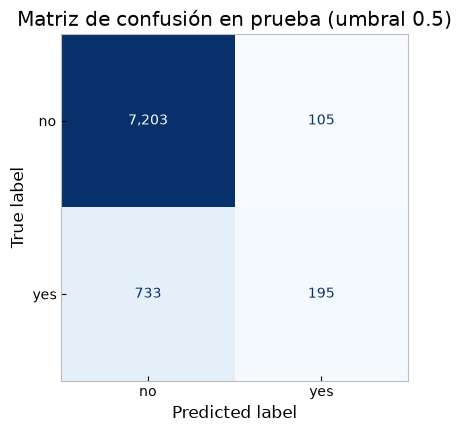

In [14]:
cm = confusion_matrix(y_test, pred_test)

fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=["no", "yes"]).plot(
    cmap="Blues", values_format=",", colorbar=False, ax=ax
)
ax.set_title("Matriz de confusión en prueba (umbral 0.5)")
ax.grid(False)
plt.show()

Como se puede apreciar en la matriz de confusión, la mayoría de los registros se concentra en los verdaderos negativos, de nuevo cargando con las consecuencias de mantener un conjunto tan desbalanceado sobre la var. objetivo. 

A partir de los conteos de clasificación con los que se construyó la matriz de confusión, calculamos métricas para evalaur el rendimiento del modelo de regresión logística:

In [15]:
tn, fp, fn, tp = cm.ravel()

print(f"Exactitud: {((tp + tn) / cm.sum()).round(4)}")
print(f"Precisión: {(tp / (tp + fp)).round(4)}")  
print(f"Sensibilidad: {(tp / (tp + fn)).round(4)}")
print(f"Especificidad: {(tn / (tn + fp)).round(4)}")
print(f"F1: {(2 * tp / (2 * tp + fp + fn)).round(4)}")


Exactitud: 0.8983
Precisión: 0.65
Sensibilidad: 0.2101
Especificidad: 0.9856
F1: 0.3176


Ahora, ya tenemos un par de métricas que no tienen un sesgo marcado hacia la clase mayoritaria. Por un lado, la sensibilidad describe la razón de verdaderos positivos sobre el total de positivos reales; por el otro, la precisión denota la razón de positivos clasificados correctamente sobre el total clasificaciones positivas, sean correctas o no; y el F1-Score, la media armónica entre estos dos. Para la solicitud que hace el banco de determinar cuáles clientes deberían ser contactados a continuación, la sensibilidad funciona mejor porque establece un estimador de que tan buena es la clasificación de positivos respecto a los casos reales, representando lo más rigurosamente posible el riesgo de usar el modelo para tomar la decisión.

## 4. Graficando Rendimiento

### 4.1. Curva ROC

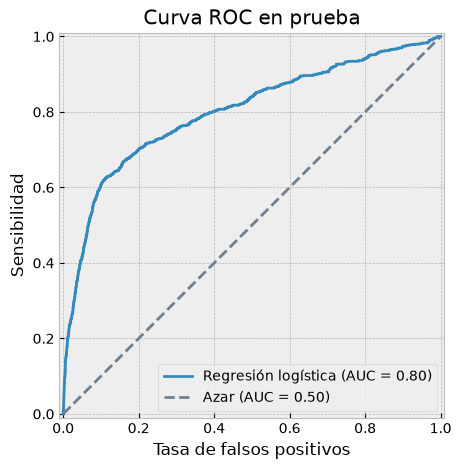

In [16]:
with plt.style.context('bmh'):
    fig, ax = plt.subplots(figsize=(6, 5))
    RocCurveDisplay.from_predictions(
        y_test, prob_test, name="Regresión logística", ax=ax
    )
    ax.plot([0, 1], [0, 1], color="slategrey", linestyle="--", label="Azar (AUC = 0.50)")
    ax.set_title("Curva ROC en prueba")
    ax.set_xlabel("Tasa de falsos positivos")
    ax.set_ylabel("Sensibilidad")
    ax.legend(loc="lower right")
    plt.show()

 La curva se mantiene por encima de la diagonal en todo su recorrido y se acerca a la esquina superior izquierda, con un AUC cercano de 0.8. Esto indica que el modelo es bueno, respecto al caso predecir aletoriamente la clase (0.5). Sin embargo, hay que notar que esta curva es insensible al desbalance de las clases.

### 4.2. Curva de precisión contra sensibilidad

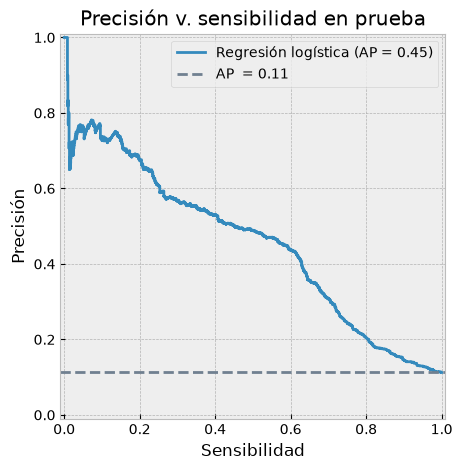

In [17]:
with plt.style.context('bmh'):
    fig, ax = plt.subplots(figsize=(6, 5))
    PrecisionRecallDisplay.from_predictions(
        y_test, prob_test, name="Regresión logística", ax=ax
    )
    ax.axhline(y_test.mean(), color="slategrey", linestyle="--",
               label=f"AP  = {(y_test.mean()).round(2)}")
    ax.set_title("Precisión v. sensibilidad en prueba")
    ax.set_xlabel("Sensibilidad")
    ax.set_ylabel("Precisión")
    ax.legend(loc="upper right")
    plt.show()

La curva ROC compara los errores contra el total de clientes que no aceptan, que son la gran mayoría; por eso, aunque el modelo haga muchas llamadas sin éxito, esos errores se ven pequeños y la curva parece buena. La precisión se mantiene cerca de 0.75 mientras la sensibilidad no supera 0.15, es decir, cuando se llama únicamente a los clientes con mayor probabilidad estimada. A partir de ahí desciende de forma sostenida hasta cerca de 0.45 con una sensibilidad de 0.6, y después cae con rapidez hasta la línea de azar (0.11), lo que indica que el último tramo de clientes que aceptan es difícil de distinguir del resto. La precisión promedio de 0.45 equivale a unas cuatro veces la de llamar al azar.

## 5. ¿Qué umbral de decisión mejora las ganancias?

La probabilidad y costo de realizar un llamada se pueden modelar como un ensayo Bernoulli, en el que cliente acepta con probabilidad $p$ y deja un ingreso de 50 y dónde la llamada cuesta 5 en cualquier caso. Entonces, la ganancia esperada de llamar es

$$50p - 5$$
$$p > 5/50 = 0.1$$

Por lo tanto, conviene llamar a todo cliente cuando se tenga una probabilidad mayor de 0.1, para así tener un superávit

Comparamos el umbral definido por el ensayo Bernoulli con uno $U= 0.5$

In [18]:
pred = (prob_test >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()

print("Umbral 0.5")
print(f"Llamadas: {tp + fp}, aceptan: {tp}, sin éxito: {fp}")
print(f"Ganancia: {45 * tp - 5 * fp}")

Umbral 0.5
Llamadas: 300, aceptan: 195, sin éxito: 105
Ganancia: 8250


In [19]:
pred = (prob_test >= 0.1).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()

print("Umbral 0.1")
print(f"Llamadas: {tp + fp}, aceptan: {tp}, sin éxito: {fp}")
print(f"Ganancia: {45 * tp - 5 * fp}")

Umbral 0.1
Llamadas: 1931, aceptan: 631, sin éxito: 1300
Ganancia: 21895


Con el umbral de 0.1 se realizan muchas más llamadas y aumentan las llamadas sin éxito, pero la ganancia del umbral menor supera por mucho al de 0.5. Conviene entonces usar un umbral pequeño (pero >0.1), que aunque deje un gran número de llamadas sin aceptar, el beneficio de aquellas respondidas supera los costos, aunque parezca más arriesgado que un umbral más conservador.

## 6. Regresión logísitica incluyendo `duration` 

Ahora incluímos la varible `duration` para ajustar el modelo de regresión logísitca:

In [20]:
X = data.drop(columns=[obj])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=ran
)

pre = ColumnTransformer([
        ("num", StandardScaler(), X_train.select_dtypes(include="number").columns),
        ("cat", OneHotEncoder(handle_unknown="ignore"), X_train.select_dtypes(exclude="number").columns),
    ])

modelo = Pipeline([
        ("preproceso", pre),
        ("modelo", LogisticRegression(max_iter=1000, random_state=ran)),
    ])

modelo = modelo.fit(X_train, y_train)

prob_test = modelo.predict_proba(X_test)[:, 1]
pred_test = (prob_test >= 0.5).astype(int)

In [21]:
tn, fp, fn, tp = cm.ravel()

print(f"Exactitud: {((tp + tn) / cm.sum()).round(4)}")
print(f"Precisión: {(tp / (tp + fp)).round(4)}")  
print(f"Sensibilidad: {(tp / (tp + fn)).round(4)}")
print(f"Especificidad: {(tn / (tn + fp)).round(4)}")
print(f"F1: {(2 * tp / (2 * tp + fp + fn)).round(4)}")


Exactitud: 0.8983
Precisión: 0.65
Sensibilidad: 0.2101
Especificidad: 0.9856
F1: 0.3176


Las métricas mejoran sustancialmente al incluir esta variable; incluso la sensibilidad lo hace. Sin embargo, como se señaló anteriormente, `duration` describe la duración de las llamadas y solo se conoce una vez que estas finalizan, lo que ignora por completo el propósito de modelar la variable objetivo, que describe quiénes han sido llamados. La inmensa mayoría, que corresponde a casos que no habían sido contactados previamente, reporta el código 999, que difiere bastante del reporte de una llamada ya realizada en condiciones normales. El modelo utilizaría entonces uno de los resultados de ya haber realizado la llamada, cuando el propósito inicial es predecir cuándo hacerla, tomando en cuenta los casos sin contacto previo; sobra decir que no serviría un modelo que incluye a dicha variable como regresor.

---

#### Declaración de uso de IA generativa

Este notebook fue elaborado con apoyo de Claude para consulta en la definición y ajuste de modelos de regresión, particularmente para establecer un pipeline de pre-procesado; igualmente, para descargar y descomprimir el archivo del *dataset* diretcamente de la Web. También se utilizó para corregir automáticamente errores ortográficos en la redacción en celdas de *markdown*.

#### Referencias

- Moro, S., Cortez, P., & Rita, P. (2014). *A data-driven approach to predict the success of bank telemarketing*. Decision Support Systems. https://doi.org/10.1016/j.dss.2014.03.001